In [32]:
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.svm import LinearSVR, SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor, StackingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from xgboost import XGBRegressor

import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem, MACCSkeys, RDKFingerprint
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
import pickle

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
#da check ka che akum mo jorr kara abal e tu wala wo Sha sahe do
# baseer khana da save data maa rowkhula aa k-fold da pora kfold da para aa 10folds folder ka cha sarangy data jora do as yah jora ka # Asad bhai h k daa daa asad bhai ok sahe 
# aa code charta dai aa save wal? aa optuna wala ta yah open ka 

In [33]:
# Load dataset
df = pd.read_csv('bandgap.csv')

In [34]:
# Load dataset
df = pd.read_csv('bandgap.csv')

# aa k-fold da pora wo dalta data na split ka wa 
# Splitting the DataFrame into 80% train and 20% test
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

# Remove rows with invalid SMILES
df = df.dropna(subset=['Smiles'])

In [35]:
# Function to compute MACCS keys
def compute_maccs_keys(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        return MACCSkeys.GenMACCSKeys(mol)
    else:
        return None

# Function to compute RDKit fingerprints
def compute_rdkit_fingerprint(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        return Chem.RDKFingerprint(mol)
    else:
        return None

# Function to compute Morgan fingerprints
def compute_morgan_fingerprint(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        return AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=1024)  # Morgan fingerprint with radius 2 and 1024 bits
    else:
        return None

# Function to compute AtomPair fingerprints
def compute_atompair_fingerprint(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        return AllChem.GetHashedAtomPairFingerprintAsBitVect(mol)
    else:
        return None

In [22]:
morgan_fps = []
maccs_fps = []
rdkit_fps = []
atompair_fps = []
valid_indices = []  # Track indices of valid SMILES
for i, smi in enumerate(df['Smiles']):
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        morgan_fps.append(compute_morgan_fingerprint(smi))
        maccs_fps.append(compute_maccs_keys(smi))
        rdkit_fps.append(compute_rdkit_fingerprint(smi))
        atompair_fps.append(compute_atompair_fingerprint(smi))
        valid_indices.append(i)

[15:32:10] Can't kekulize mol.  Unkekulized atoms: 11 13 14 15 16 17 18
[15:32:10] Can't kekulize mol.  Unkekulized atoms: 25 27 28 29 30 31 32
[15:32:10] Explicit valence for atom # 5 B, 4, is greater than permitted
[15:32:13] Explicit valence for atom # 16 N, 4, is greater than permitted
[15:32:13] Explicit valence for atom # 5 B, 4, is greater than permitted
[15:32:13] Explicit valence for atom # 5 B, 4, is greater than permitted
[15:32:13] Explicit valence for atom # 5 B, 4, is greater than permitted
[15:32:13] Explicit valence for atom # 5 B, 4, is greater than permitted
[15:32:13] Explicit valence for atom # 5 B, 4, is greater than permitted
[15:32:13] Explicit valence for atom # 16 C, 5, is greater than permitted
[15:32:13] Can't kekulize mol.  Unkekulized atoms: 40
[15:32:14] Explicit valence for atom # 27 B, 4, is greater than permitted
[15:32:14] Explicit valence for atom # 17 B, 4, is greater than permitted
[15:32:14] Explicit valence for atom # 17 B, 4, is greater than perm

In [23]:
morgan_fps = []
maccs_fps = []
rdkit_fps = []
atompair_fps = []
valid_indices = []  # Track indices of valid SMILES
for i, smi in enumerate(df['Smiles']):
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        morgan_fps.append(compute_morgan_fingerprint(smi))
        maccs_fps.append(compute_maccs_keys(smi))
        rdkit_fps.append(compute_rdkit_fingerprint(smi))
        atompair_fps.append(compute_atompair_fingerprint(smi))
        valid_indices.append(i)

[15:32:46] Can't kekulize mol.  Unkekulized atoms: 11 13 14 15 16 17 18
[15:32:46] Can't kekulize mol.  Unkekulized atoms: 25 27 28 29 30 31 32
[15:32:46] Explicit valence for atom # 5 B, 4, is greater than permitted
[15:32:49] Explicit valence for atom # 16 N, 4, is greater than permitted
[15:32:49] Explicit valence for atom # 5 B, 4, is greater than permitted
[15:32:49] Explicit valence for atom # 5 B, 4, is greater than permitted
[15:32:49] Explicit valence for atom # 5 B, 4, is greater than permitted
[15:32:49] Explicit valence for atom # 5 B, 4, is greater than permitted
[15:32:49] Explicit valence for atom # 5 B, 4, is greater than permitted
[15:32:49] Explicit valence for atom # 16 C, 5, is greater than permitted
[15:32:50] Can't kekulize mol.  Unkekulized atoms: 40
[15:32:50] Explicit valence for atom # 27 B, 4, is greater than permitted
[15:32:50] Explicit valence for atom # 17 B, 4, is greater than permitted
[15:32:50] Explicit valence for atom # 17 B, 4, is greater than perm

In [24]:
# Filter dataframe based on valid indices
df = df.iloc[valid_indices]

# Split the dataset into training and testing sets for each type of fingerprint
X_morgan_train, X_morgan_test, y_train, y_test = train_test_split(morgan_fps, df['BG'], test_size=0.2, random_state=42)
X_maccs_train, X_maccs_test, _, _ = train_test_split(maccs_fps, df['BG'], test_size=0.2, random_state=42)
X_rdkit_train, X_rdkit_test, _, _ = train_test_split(rdkit_fps, df['BG'], test_size=0.2, random_state=42)
X_atompair_train, X_atompair_test, _, _ = train_test_split(atompair_fps, df['BG'], test_size=0.2, random_state=42)

In [27]:
#label h define na di 
import numpy as np
save_dir_folds = '/home/basir/basir/BandGap/folds/'
morgan_fps = []
maccs_fps = []
rdkit_fps = []
atompair_fps = []
np.save(save_dir_folds + 'morgan_fps.npy', morgan_fps)
np.save(save_dir_folds + 'maccs_fps.npy', maccs_fps)
np.save(save_dir_folds + 'rdkit_fps.npy', rdkit_fps)
np.save(save_dir_folds + 'atompair_fps.npy', atompair_fps)
np.save(save_dir_folds + 'labels.npy', df['BG']) # da ka data walay nashta? 

In [41]:
import numpy as np

# Define the directory where the files are saved
# load_dir = '/home/basir/basir/BandGap/Labels/'
save_dir_folds = '/home/basir/basir/BandGap/folds/'

# Load the data splits
atompair_fps = np.load(save_dir_folds + 'atompair_fps.npy')
maccs_fps = np.load(save_dir_folds + 'maccs_fps.npy')
morgan_fps = np.load(save_dir_folds + 'morgan_fps.npy')
rdkit_fps = np.load(save_dir_folds + 'rdkit_fps.npy')
labels = np.load(save_dir_folds + 'labels.npy')


In [42]:
#  rdkitX = rdkit_fps
#  Y = labels

array([[0, 0, 0, ..., 1, 1, 0],
       [0, 0, 0, ..., 1, 1, 0],
       [0, 0, 0, ..., 1, 1, 0],
       ...,
       [0, 0, 0, ..., 1, 1, 0],
       [0, 0, 0, ..., 1, 1, 0],
       [0, 0, 0, ..., 1, 1, 0]])

(285, 167)

In [69]:
import numpy as np
from sklearn.ensemble import StackingRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import joblib

# Load the data splits for RDKit fingerprint type
load_dir = '/home/basir/basir/BandGap/Labels/'
X_rdkit_train = np.load(load_dir + 'X_rdkit_train.npy')
X_rdkit_test = np.load(load_dir + 'X_rdkit_test.npy')
y_train = np.load(load_dir + 'y_train.npy')
y_test = np.load(load_dir + 'y_test.npy')

# Define the models with their best hyperparameters for RDKit fingerprint
models = {
    'Random Forest': RandomForestRegressor(n_estimators=257, max_depth=19, min_samples_split=2, 
                                            min_samples_leaf=1, max_features='sqrt', max_leaf_nodes=51,
                                            min_impurity_decrease=0.00040098281840123017, random_state=0, 
                                            ccp_alpha=0.0001583895499599814),
    'SVR': SVR(C=5.478815635690611, cache_size=764.1151282729807, coef0=0.5904579794546133, degree=4,
               epsilon=0.11390268675101414, kernel='poly', max_iter=250, shrinking=True, tol=0.08487181333906076),
    'Gradient Boosting': GradientBoostingRegressor(learning_rate=0.08839188535312976, max_depth=20,
                                                    max_features='log2', max_leaf_nodes=15,
                                                    min_impurity_decrease=0.01825443987192928,
                                                    min_samples_leaf=3, min_samples_split=9,
                                                    n_estimators=332, random_state=49,
                                                    subsample=0.84854690409174),
    'AdaBoost': AdaBoostRegressor(learning_rate=0.5853530174681943, n_estimators=100, random_state=53),
    'XGBoost': XGBRegressor(base_score=None, booster=None, colsample_bylevel=0.5251103597669132,
                             colsample_bynode=0.54103283038997, colsample_bytree=0.7096138076061271,
                             gamma=None, gpu_id=2, learning_rate=0.06550724337222495, max_depth=14,
                             max_leaves=None, min_child_weight=None, missing=np.nan,
                             n_estimators=411, num_parallel_tree=None, objective='reg:squarederror',
                             reg_alpha=None, reg_lambda=None, scale_pos_weight=None, tree_method='hist',
                             verbosity=None),
    'KNeighbors': KNeighborsRegressor(leaf_size=29, p=1, weights='distance')
}

# Define the stacking regressor with the above models and Linear Regression as the final estimator
stacking_regressor_rdkit = StackingRegressor(estimators=list(models.items()), final_estimator=LinearRegression())

# Train the stacking regressor for RDKit fingerprint
stacking_regressor_rdkit.fit(X_rdkit_train, y_train)

# Evaluate the stacking regressor
y_pred_rdkit = stacking_regressor_rdkit.predict(X_rdkit_test)
r2_rdkit = r2_score(y_test, y_pred_rdkit)
mae_rdkit = mean_absolute_error(y_test, y_pred_rdkit)

# Save the stacking regressor model for RDKit fingerprint
model_path_rdkit = '/home/basir/basir/BandGap/Labels/rdkit_stacking_regressor.joblib'
joblib.dump(stacking_regressor_rdkit, model_path_rdkit)

print("RDKit Fingerprint Stacking Regressor:")
print(f"  R^2 score: {r2_rdkit}")
print(f"  Mean Absolute Error: {mae_rdkit}")


RDKit Fingerprint Stacking Regressor:
  R^2 score: 0.8144243420516863
  Mean Absolute Error: 0.1106920647535008


In [67]:
import numpy as np
from sklearn.ensemble import StackingRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold
import joblib

# Load the data splits for RDKit fingerprint type
load_dir = '/home/basir/basir/BandGap/Labels/'
X_rdkit_train = np.load(load_dir + 'X_rdkit_train.npy')
X_rdkit_test = np.load(load_dir + 'X_rdkit_test.npy')
y_train = np.load(load_dir + 'y_train.npy')
y_test = np.load(load_dir + 'y_test.npy')

# Define the models with their best hyperparameters for RDKit fingerprint
models = {
    'Random Forest': RandomForestRegressor(n_estimators=50, max_depth=5, min_samples_split=2, 
                                            min_samples_leaf=1, max_features='sqrt', max_leaf_nodes=11,
                                           min_impurity_decrease=0.00040098281840123017, random_state=49, 
                                           ccp_alpha=0.0001583895499599814),
    'SVR': SVR(C=100.478815635690611, cache_size=764.1151282729807, coef0=0.5904579794546133, degree=4,
               epsilon=0.11390268675101414, kernel='poly', max_iter=250, shrinking=False, tol=0.08487181333906076),
    #'Gradient Boosting': GradientBoostingRegressor(learning_rate=0.08839188535312976, max_depth=5,
                                                   # max_features='log2', max_leaf_nodes=11,
                                                   # min_impurity_decrease=0.01825443987192928,
                                                   #min_samples_leaf=3, min_samples_split=9,
                                                   # n_estimators=50, random_state=49,
                                                   # subsample=0.84854690409174),
    'AdaBoost': AdaBoostRegressor(learning_rate=0.5853530174681943, n_estimators=50, random_state=49),
    'XGBoost': XGBRegressor(base_score=None, booster=None, colsample_bylevel=0.5251103597669132,
                             colsample_bynode=0.54103283038997, colsample_bytree=0.7096138076061271,
                             gamma=None, gpu_id=2, learning_rate=0.06550724337222495, max_depth=5,
                             max_leaves=None, min_child_weight=None, missing=np.nan,
                             n_estimators=50, num_parallel_tree=None, objective='reg:squarederror',
                             reg_alpha=1, reg_lambda=1, scale_pos_weight=None, tree_method='hist',
                             verbosity=None),
    #'KNeighbors': KNeighborsRegressor(leaf_size=9, p=1, weights='distance')
}

# Define k-fold cross-validation
kfold = KFold(n_splits=10, shuffle=True, random_state=113)

# Initialize lists to store MAE and R2 scores for each fold
mae_scores = []
r2_scores = []

# Perform k-fold cross-validation
for fold, (train_idx, val_idx) in enumerate(kfold.split(rdkit_fps), 1):
    X_train_fold, X_val_fold = rdkit_fps[train_idx], rdkit_fps[val_idx]
    y_train_fold, y_val_fold = labels[train_idx], labels[val_idx]

    # Define the stacking regressor with the above models and Linear Regression as the final estimator
    stacking_regressor_rdkit = StackingRegressor(estimators=list(models.items()), final_estimator=LinearRegression())

    # Train the stacking regressor for RDKit fingerprint
    stacking_regressor_rdkit.fit(X_train_fold, y_train_fold)

    # Evaluate the stacking regressor
    y_pred_fold = stacking_regressor_rdkit.predict(X_val_fold)
    r2_fold = r2_score(y_val_fold, y_pred_fold)
    mae_fold = mean_absolute_error(y_val_fold, y_pred_fold)

    # Save scores for this fold
    r2_scores.append(r2_fold)
    mae_scores.append(mae_fold)

    # Display results for this fold
    print(f"Fold {fold}:")
    print(f"  R^2 score: {r2_fold}")
    print(f"  Mean Absolute Error: {mae_fold}")

# Calculate and display average scores over all folds
avg_r2 = np.mean(r2_scores)
avg_mae = np.mean(mae_scores)
print("\nAverage scores over all folds:")
print(f"  Average R^2 score: {avg_r2}")
print(f"  Average Mean Absolute Error: {avg_mae}")

# Train the stacking regressor on the full training set
stacking_regressor_rdkit.fit(X_rdkit_train, y_train)

# Evaluate the stacking regressor on the test set
y_pred_rdkit_test = stacking_regressor_rdkit.predict(X_rdkit_test)
r2_rdkit_test = r2_score(y_test, y_pred_rdkit_test)
mae_rdkit_test = mean_absolute_error(y_test, y_pred_rdkit_test)

# Save the stacking regressor model for RDKit fingerprint
model_path_rdkit = '/home/basir/basir/BandGap/Labels/rdkit_stacking_regressor.joblib'
joblib.dump(stacking_regressor_rdkit, model_path_rdkit)

print("\nRDKit Fingerprint Stacking Regressor (trained on full training set):")
print(f"  R^2 score on test set: {r2_rdkit_test}")
print(f"  Mean Absolute Error on test set: {mae_rdkit_test}")


Fold 1:
  R^2 score: 0.35942052693975257
  Mean Absolute Error: 0.11656619717965919
Fold 2:
  R^2 score: 0.27782537213383973
  Mean Absolute Error: 0.17004624816924077
Fold 3:
  R^2 score: 0.4344057667513508
  Mean Absolute Error: 0.1713696667225534
Fold 4:
  R^2 score: 0.5994275453380277
  Mean Absolute Error: 0.14921888423946614
Fold 5:
  R^2 score: 0.6976050843683557
  Mean Absolute Error: 0.11798662806724351
Fold 6:
  R^2 score: 0.6971808371741226
  Mean Absolute Error: 0.18412547937443025
Fold 7:
  R^2 score: 0.3955229321592568
  Mean Absolute Error: 0.23534052057147362
Fold 8:
  R^2 score: 0.4442616825746828
  Mean Absolute Error: 0.12410080610468373
Fold 9:
  R^2 score: 0.7575490067940559
  Mean Absolute Error: 0.13880254480219298
Fold 10:
  R^2 score: 0.7430527767196773
  Mean Absolute Error: 0.160974758281208

Average scores over all folds:
  Average R^2 score: 0.5406251530953121
  Average Mean Absolute Error: 0.15685317335121515

RDKit Fingerprint Stacking Regressor (trained 

In [8]:
X_rdkit_train .shape

(228, 2048)

In [7]:
X_rdkit_test.shape

(57, 2048)

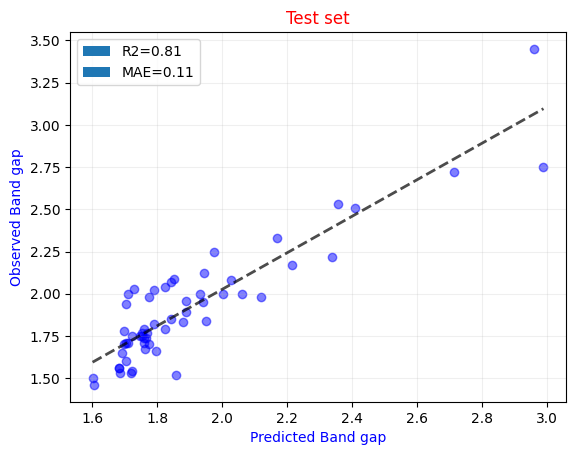

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches

# Plot
sns.regplot(x=y_pred_rdkit_test, y=y_test, scatter_kws={"color": "blue", "alpha":0.5}, line_kws={"lw":2,'ls':'--','color':'black',"alpha":0.7}, ci=None)
plt.xlabel('Predicted Band gap', color='blue')
plt.ylabel('Observed Band gap', color='blue')
plt.title("Test set", color='red')
plt.grid(alpha=0.2)
R2 = mpatches.Patch(label="R2={:04.2f}".format(r2_rdkit))
MAE = mpatches.Patch(label="MAE={:04.2f}".format(mae_rdkit))
plt.legend(handles=[R2, MAE])
plt.show()

In [3]:
import numpy as np
from sklearn.ensemble import StackingRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold
import joblib

# Load the data splits for Morgan fingerprint type
load_dir = '/home/basir/basir/BandGap/Labels/'
X_morgan_train = np.load(load_dir + 'X_morgan_train.npy')
X_morgan_test = np.load(load_dir + 'X_morgan_test.npy')

# Define the models with their best hyperparameters for Morgan fingerprint
models = {
    'Random Forest': RandomForestRegressor(n_estimators=257, max_depth=19, min_samples_split=2, 
                                            min_samples_leaf=1, max_features='sqrt', max_leaf_nodes=51,
                                            min_impurity_decrease=0.00040098281840123017, random_state=0),
    'SVR': SVR(C=5.478815635690611, cache_size=764.1151282729807, coef0=0.5904579794546133, degree=4,
               epsilon=0.11390268675101414, kernel='poly', max_iter=250, shrinking=False, tol=0.08487181333906076),
    'Gradient Boosting': GradientBoostingRegressor(learning_rate=0.08839188535312976, max_depth=20,
                                                    max_features='log2', max_leaf_nodes=15,
                                                    min_impurity_decrease=0.01825443987192928,
                                                    min_samples_leaf=3, min_samples_split=9,
                                                    n_estimators=332, random_state=49,
                                                    subsample=0.84854690409174),
    'AdaBoost': AdaBoostRegressor(learning_rate=0.5853530174681943, n_estimators=369, random_state=53),
    'XGBoost': XGBRegressor(base_score=None, booster=None, colsample_bylevel=0.5251103597669132,
                             colsample_bynode=0.54103283038997, colsample_bytree=0.7096138076061271,
                             gamma=None, gpu_id=2, learning_rate=0.06550724337222495, max_depth=14,
                             max_leaves=None, min_child_weight=None, missing=np.nan,
                             n_estimators=411, num_parallel_tree=None, objective='reg:squarederror',
                             reg_alpha=None, reg_lambda=None, scale_pos_weight=None, tree_method='hist',
                             verbosity=None),
    'KNeighbors': KNeighborsRegressor(leaf_size=29, p=1, weights='distance')
}

# Define k-fold cross-validation
kfold = KFold(n_splits=10, shuffle=True, random_state=42)

# Initialize lists to store MAE and R2 scores for each fold
mae_scores = []
r2_scores = []

# Perform k-fold cross-validation
for fold, (train_idx, val_idx) in enumerate(kfold.split(X_morgan_train), 1):
    X_train_fold, X_val_fold = X_morgan_train[train_idx], X_morgan_train[val_idx]
    y_train_fold, y_val_fold = y_train[train_idx], y_train[val_idx]

    # Define the stacking regressor with the above models and Linear Regression as the final estimator
    stacking_regressor_morgan = StackingRegressor(estimators=list(models.items()), final_estimator=LinearRegression())

    # Train the stacking regressor for Morgan fingerprint
    stacking_regressor_morgan.fit(X_train_fold, y_train_fold)

    # Evaluate the stacking regressor
    y_pred_fold = stacking_regressor_morgan.predict(X_val_fold)
    r2_fold = r2_score(y_val_fold, y_pred_fold)
    mae_fold = mean_absolute_error(y_val_fold, y_pred_fold)

    # Save scores for this fold
    r2_scores.append(r2_fold)
    mae_scores.append(mae_fold)

    # Display results for this fold
    print(f"Fold {fold}:")
    print(f"  R^2 score: {r2_fold}")
    print(f"  Mean Absolute Error: {mae_fold}")

# Calculate and display average scores over all folds
avg_r2 = np.mean(r2_scores)
avg_mae = np.mean(mae_scores)
print("\nAverage scores over all folds:")
print(f"  Average R^2 score: {avg_r2}")
print(f"  Average Mean Absolute Error: {avg_mae}")

# Train the stacking regressor on the full training set
stacking_regressor_morgan.fit(X_morgan_train, y_train)

# Evaluate the stacking regressor on the test set
y_pred_morgan_test = stacking_regressor_morgan.predict(X_morgan_test)
r2_morgan_test = r2_score(y_test, y_pred_morgan_test)
mae_morgan_test = mean_absolute_error(y_test, y_pred_morgan_test)

# Save the stacking regressor model for Morgan fingerprint
model_path_morgan = '/home/basir/basir/BandGap/Labels/morgan_stacking_regressor.joblib'
joblib.dump(stacking_regressor_morgan, model_path_morgan)

print("\nMorgan Fingerprint Stacking Regressor (trained on full training set):")
print(f"  R^2 score on test set: {r2_morgan_test}")
print(f"  Mean Absolute Error on test set: {mae_morgan_test}")


/home/basir/anaconda3/envs/Xgboost3.8/lib/python3.8/site-packages/xgboost/core.py:160: UserWarning: [17:30:34] WARNING: /workspace/src/common/error_msg.cc:45: `gpu_id` is deprecated since2.0.0, use `device` instead. E.g. device=cpu/cuda/cuda:0
  warnings.warn(smsg, UserWarning)
/home/basir/anaconda3/envs/Xgboost3.8/lib/python3.8/site-packages/xgboost/core.py:160: UserWarning: [17:30:45] WARNING: /workspace/src/common/error_msg.cc:58: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:2, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  warnings.warn(smsg, UserWarning)


Fold 1:
  R^2 score: 0.28513635371272794
  Mean Absolute Error: 0.24637285734128186
Fold 2:
  R^2 score: 0.6557245615189897
  Mean Absolute Error: 0.1683274618475993
Fold 3:
  R^2 score: 0.659019816615467
  Mean Absolute Error: 0.12578461209666852
Fold 4:
  R^2 score: 0.4877440539523843
  Mean Absolute Error: 0.1819693045038626
Fold 5:
  R^2 score: 0.6062683808033089
  Mean Absolute Error: 0.15391993445508034
Fold 6:
  R^2 score: 0.7304557911182181
  Mean Absolute Error: 0.10426616797929701
Fold 7:
  R^2 score: -0.3894512538340207
  Mean Absolute Error: 0.19778511935742288
Fold 8:
  R^2 score: 0.32778374878072714
  Mean Absolute Error: 0.1502466739293979
Fold 9:
  R^2 score: 0.24824013823364832
  Mean Absolute Error: 0.18487056092852214
Fold 10:
  R^2 score: 0.41845069196942497
  Mean Absolute Error: 0.14992119901579448

Average scores over all folds:
  Average R^2 score: 0.40293722828708756
  Average Mean Absolute Error: 0.1663463891454927

Morgan Fingerprint Stacking Regressor (train

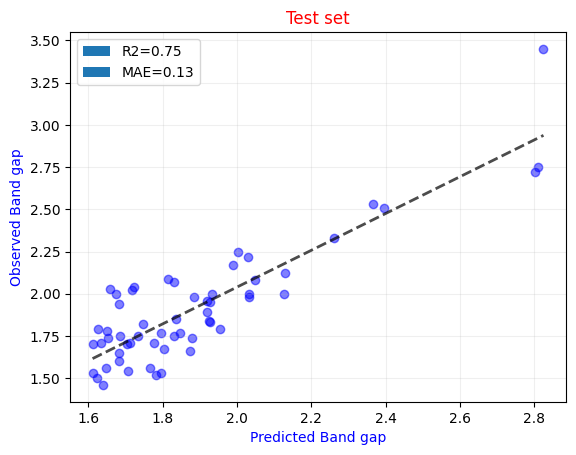

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches

# Plot
sns.regplot(x=y_pred_morgan_test, y=y_test, scatter_kws={"color": "blue", "alpha":0.5}, line_kws={"lw":2,'ls':'--','color':'black',"alpha":0.7}, ci=None)
plt.xlabel('Predicted Band gap', color='blue')
plt.ylabel('Observed Band gap', color='blue')
plt.title("Test set", color='red')
plt.grid(alpha=0.2)
R2 = mpatches.Patch(label="R2={:04.2f}".format(r2_morgan_test))
MAE = mpatches.Patch(label="MAE={:04.2f}".format(mae_morgan_test))
plt.legend(handles=[R2, MAE])
plt.show()